# CausalBridges-10b — Effets de traitement individuels : TARNet et CFRNet

[← Série Causal-Bridges](README.md) | [CB-10 Automated Social Science ←](CausalBridges-10-Automated-Social-Science.ipynb)

**Ce carnet est le pli 3 de l'extension Origami de la série** (EPIC [#19309](https://github.com/jsboige/CoursIA/issues/19309)) : après l'essai ciblé (pli 2), il attaque l'angle mort du **CATE** — l'effet de traitement n'est pas un nombre, c'est une **fonction de l'individu**, et les estimateurs classiques plafonnent sur cette fonction.

L'enjeu pratique est direct : un médecin ne traite pas « la population » de la lombalgie, il traite un patient ; une politique publique ne subventionne pas « les demandeurs d'emploi », elle cible des profils. Savoir *si* un traitement marche en moyenne ne dit pas *pour qui*. Ce carnet mesure ce saut : sur le banc **IHDP**, les estimateurs classiques (OLS, IPTW, doubly-robust) atteignent leurs limites sur la métrique qui compte pour l'individualisation — **PEHE** (*Precision in Estimation of Heterogeneous Effect*) — et deux architectures neuroniques dédiées, **TARNet** et **CFRNet** (Shalit, Johansson & Sontag, 2017), les dépassent en apprenant des représentations partagées entre les deux bras. Le verdict est ensuite confronté à un second banc — trois simulations du data challenge **ACIC 2016** (Dorie et al. 2019), où propension, part traitée et hétérogénéité varient — pour mesurer ce qui survit d'un banc à l'autre.

> **Note de numérotation** : le carnet prend la lettre d'accrétion `10b` — `CausalBridges-10-Automated-Social-Science` occupe déjà le numéro 10 nu depuis la PR #21210 (convention `.claude/rules/notebook-accretion-numbering.md`, collision d'identifiant).

## Objectifs d'apprentissage

À l'issue de ce carnet, le lecteur est capable de :

1. **Définir le CATE** $\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X=x]$ et le distinguer de l'ATE ;
2. **Chargeur et vérifier** un banc semi-synthétique avec vérité terrain (IHDP : *inflated* outcomes, *biased* treatment assignment) ;
3. **Implémenter cinq baselines** — OLS-X, T-Learner, S-Learner, IPTW, doubly-robust — et diagnostiquer *où* elles plafonnent ;
4. **Écrire TARNet from scratch** en PyTorch : tronc partagé + deux têtes, l'argument de représentation de Shalit et al. ;
5. **Écrire CFRNet** : la pénalité IPM (MMD à noyau linéaire) entre représentations des deux bras, et mesurer ce qu'elle change ;
6. **Mesurer** avec PEHE et erreur d'ATE sur 5 graines, lire un tableau de verdict honnête (médiane + IQR, pas un chiffre unique) ;
7. **Confronter le verdict à un second banc** (ACIC 2016 : trois simulations, licence CDLA-Sharing-1.0) — ce qui survit du classement IHDP quand propension et hétérogénéité changent.

## Navigation

1. **Motivation** — pourquoi l'ATE ne suffit pas, et ce que « plafonner » veut dire
2. **Le banc IHDP** — provenance, colonnes, vérité terrain, splits
3. **Les baselines classiques** — OLS-X, T-Learner, S-Learner, IPTW, doubly-robust
4. **Pourquoi elles plafonnent** — biais de sélection dans l'espace des covariables
5. **TARNet** — tronc partagé, deux têtes, entraînement
6. **CFRNet** — la pénalité IPM et son effet mesuré
7. **Benchmark 5 graines** — PEHE, erreur d'ATE, tableau de verdict
8. **Verdict** — quand le neuronal gagne, quand il ne gagne pas
9. **Second banc ACIC 2016** — provenance, licence, trois simulations, verdict croisé
10. **Exercices** — cinq prolongements guidés

## 1. Motivation — l'effet n'est pas un nombre, c'est une fonction

Un essai randomisé mesure un **ATE** : la différence moyenne entre les deux bras. Utile pour décider *si* on traite, inutile pour décider *qui* traiter. Le CATE raffine la question :

$$\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$$

Deux régimes de difficulté se cachent derrière cette définition :

- **Le régime où les covariables expliquent l'hétérogénéité** : l'effet varie systématiquement avec $x$ (âge, sévérité), et un modèle bien spécifié peut le retrouver.
- **Le régime où le traitement est sélectionné** : les individus traités ne ressemblent pas aux contrôles ($e(x) = P(T=1 \mid X=x)$ loin de 0,5), et toute erreur de spécification se paie sur les régions où un seul bras est observé.

Sur IHDP, les deux régimes coexistent : le traitement est **biaisé par construction** (les enfants à risque plus élevé sont plus souvent traités) et l'outcome a été **gonflé** de façon non linéaire. C'est exactement le terrain où les estimateurs classiques plafonnent — et où l'argument de représentation de Shalit et al. (2017) intervient : *si l'on apprend une représentation $\Phi(x)$ dans laquelle les distributions des deux bras se ressemblent, alors un modèle d'outcome simple sur $\Phi$ estime mieux le contrefactuel.*

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 2026
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 120)
print("environnement pret")

environnement pret


## 2. Le banc IHDP — données, vérité terrain, splits

**Provenance** : Hill (2011), *Bayesian Nonparametric Modeling for Causal Inference*, JCGS — version semi-synthétique du Infant Health and Development Program (IHDP), 747 unités, 25 covariables (6 continues, 19 binaires). Le fichier utilisé ici est la réplique 1 du banc standard (`ihdp_npci_1.csv`, format du dépôt CEVAE), committé sous `data/ihdp/` avec son empreinte :

| propriété | valeur |
|---|---|
| fichier | `data/ihdp/ihdp_npci_1.csv` |
| sha256 | `2bdc8b94fdf2f669b1d3d49325fd9359d88418566545003867841312a1653411` |
| lignes × colonnes | 747 × 30 |
| layout | `t, y_factual, y_cfactual, mu0, mu1, x1..x25` |

**La vérité terrain est connue** : $\tau_i = \mu_{1i} - \mu_{0i}$ pour chaque unité, et $y_{\text{factual}}$ est l'outcome observé ($y_{\text{cf}}$ est le contrefactuel latent, jamais observé par le praticien — il ne sert qu'à la mesure).

Attention au sens de lecture : en situation réelle, seuls `t`, `y_factual` et `x` seraient disponibles. `mu0`, `mu1`, `y_cfactual` sont l'**étalon de mesure** du banc, pas des entrées du modèle.

n = 747 unites | traites = 139 (18.6%) | controles = 608
covariables : 25

CATE vrai : moyenne 4.016 | ecart-type 0.859 | min -1.87 | max 4.67
ATE vrai  : 4.016  (le chiffre que l'essai randomise estimerait)


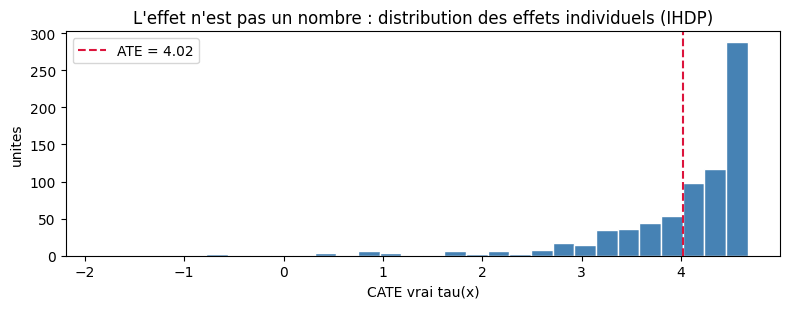

In [2]:
from pathlib import Path

DATA = Path("data/ihdp/ihdp_npci_1.csv")
raw = np.loadtxt(DATA, delimiter=",")
t = raw[:, 0].astype(int)          # traitement
y = raw[:, 1]                       # outcome observe (factual)
mu0, mu1 = raw[:, 3], raw[:, 4]     # moyennes contrefactuelles (verite terrain)
X = raw[:, 5:]                      # 25 covariables (6 continues + 19 binaires)
tau = mu1 - mu0                     # CATE vrai, par unite

print(f"n = {len(t)} unites | traites = {t.sum()} ({t.mean():.1%}) | controles = {(1-t).sum()}")
print(f"covariables : {X.shape[1]}")
print()
print("CATE vrai : moyenne %.3f | ecart-type %.3f | min %.2f | max %.2f"
      % (tau.mean(), tau.std(), tau.min(), tau.max()))
print("ATE vrai  : %.3f  (le chiffre que l'essai randomise estimerait)" % tau.mean())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(tau, bins=30, color="steelblue", edgecolor="white")
ax.axvline(tau.mean(), color="crimson", ls="--", label=f"ATE = {tau.mean():.2f}")
ax.set_xlabel("CATE vrai tau(x)"); ax.set_ylabel("unites")
ax.set_title("L'effet n'est pas un nombre : distribution des effets individuels (IHDP)")
ax.legend(); plt.tight_layout(); plt.show()

**Lecture** : l'ATE vaut environ 4 ; mais l'écart-type des effets individuels est du même ordre. Un estimateur qui rend un chiffre constant se trompe donc sur une large part des unités — c'est précisément ce que PEHE mesurera. Le traitement n'est pas aléatoire : les unités traitées ont des covariables différentes — la propension estimée le confirmera à la section 3.

### Le protocole d'évaluation

- **Split aléatoire stratifié** 70 % entraînement / 30 % test, répété sur **5 graines** — la graine contrôle à la fois le split et l'initialisation des réseaux.
- **Métriques sur le test uniquement**, contre la vérité terrain :
  - $\varepsilon_{PEHE} = \sqrt{\frac{1}{n}\sum_i (\hat\tau(x_i) - \tau(x_i))^2}$ (en unités de l'outcome — plus bas est mieux) ;
  - $\varepsilon_{ATE} = |\overline{\hat\tau} - \overline{\tau}|$.
- Le split standard de la littérature CFRNet est 63/27/10 (train/valid/test) ; nous utilisons **70/30** sans ensemble de validation (pas d'early stopping) — plus de 220 unités de test au lieu de 75, donc des métriques moins bruitées. C'est une déviation **déclarée** : les valeurs absolues ne sont pas comparables ligne à ligne aux tableaux de Shalit et al., les **écarts entre méthodes** le sont.

In [3]:
def split_train_test(t, X, y, mu0, mu1, tau, seed, frac_train=0.70):
    # split stratifie sur le traitement (reproductible par graine)
    rng = np.random.default_rng(seed)
    tr_idx, te_idx = [], []
    for arm in (0, 1):
        idx = np.where(t == arm)[0]
        rng.shuffle(idx)
        k = int(round(frac_train * len(idx)))
        tr_idx.append(idx[:k]); te_idx.append(idx[k:])
    tr = np.concatenate(tr_idx); te = np.concatenate(te_idx)
    return (X[tr], t[tr], y[tr], mu0[tr], mu1[tr], tau[tr],
            X[te], t[te], y[te], mu0[te], mu1[te], tau[te])

# Controle du split a la graine de reference
(Xtr, ttr, ytr, mu0tr, mu1tr, tautr,
 Xte, tte, yte, mu0te, mu1te, taute) = split_train_test(t, X, y, mu0, mu1, tau, seed=RNG_SEED)
print(f"train : {len(ttr)} ({ttr.mean():.1%} traites) | test : {len(tte)} ({tte.mean():.1%} traites)")

train : 523 (18.5% traites) | test : 224 (18.8% traites)


## 3. Les baselines classiques — cinq réflexes, cinq plafonds

| estimateur | idée | ce qu'il peut capter du CATE |
|---|---|---|
| **OLS-X** | une régression linéaire avec $t$ en régresseur | un effet **constant** (le coefficient de $t$) |
| **T-Learner** | un modèle par bras : $\hat\mu_1(x) - \hat\mu_0(x)$ | toute hétérogénéité que les modèles peuvent exprimer |
| **S-Learner** | un seul modèle avec $t$ parmi les entrées | hétérogénéité seulement si le modèle la trouve sans la forcer |
| **IPTW** | repondération par $1/e(x)$ puis différence pondérée | un effet **marginal** (constant), corrigé du biais de sélection |
| **Doubly-robust (AIPW)** | outcome model **et** propension combinés | pseudo-effets individuels $\hat\tau_i$, doublement protégés |

Les modèles d'outcome non linéaires utilisés ici sont des **arbres boostés** (`GradientBoostingRegressor`) : c'est le « meilleur estimateur classique raisonnable » sans ingénierie neuronique — le plafond qu'on veut mesurer.

In [4]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression

GB_KW = dict(n_estimators=100, max_depth=3, min_samples_leaf=5, random_state=0)

def est_ols_x(Xtr, ttr, ytr, Xte):
    m = LinearRegression().fit(np.column_stack([Xtr, ttr]), ytr)
    coef_t = m.coef_[-1]
    return np.full(len(Xte), coef_t)

def est_t_learner(Xtr, ttr, ytr, Xte):
    m1 = GradientBoostingRegressor(**GB_KW).fit(Xtr[ttr == 1], ytr[ttr == 1])
    m0 = GradientBoostingRegressor(**GB_KW).fit(Xtr[ttr == 0], ytr[ttr == 0])
    return m1.predict(Xte) - m0.predict(Xte)

def est_s_learner(Xtr, ttr, ytr, Xte):
    m = GradientBoostingRegressor(**GB_KW).fit(np.column_stack([Xtr, ttr]), ytr)
    X1 = np.column_stack([Xte, np.ones(len(Xte))])
    X0 = np.column_stack([Xte, np.zeros(len(Xte))])
    return m.predict(X1) - m.predict(X0)

def _propensity(Xtr, ttr, Xte):
    e = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr, ttr).predict_proba(Xte)[:, 1]
    return np.clip(e, 1e-3, 1 - 1e-3)

def est_iptw(Xtr, ttr, ytr, Xte):
    e = _propensity(Xtr, ttr, Xte)
    # un effet marginal constant : la difference ponderee estime l'ATE
    w1 = ttr / np.clip(_propensity(Xtr, ttr, Xtr), 1e-3, 1 - 1e-3)
    w0 = (1 - ttr) / np.clip(_propensity(Xtr, ttr, Xtr), 1e-3, 1 - 1e-3)
    ate = np.sum(w1 * ytr) / np.sum(w1) - np.sum(w0 * ytr) / np.sum(w0)
    return np.full(len(Xte), ate)

def est_dr(Xtr, ttr, ytr, Xte):
    # AIPW : pseudo-effets individuels, doublement robustes
    m1 = GradientBoostingRegressor(**GB_KW).fit(Xtr[ttr == 1], ytr[ttr == 1])
    m0 = GradientBoostingRegressor(**GB_KW).fit(Xtr[ttr == 0], ytr[ttr == 0])
    e_tr = np.clip(_propensity(Xtr, ttr, Xtr), 1e-3, 1 - 1e-3)
    e_te = np.clip(_propensity(Xtr, ttr, Xte), 1e-3, 1 - 1e-3)
    mu1_hat, mu0_hat = m1.predict(Xte), m0.predict(Xte)
    mu1_tr, mu0_tr = m1.predict(Xtr), m0.predict(Xtr)
    # correction AIPW agregee : tau(x) = mu1-mu0 + residus ponderes (calibration globale)
    corr = (np.sum(ttr * (ytr - mu1_tr) / e_tr) / np.sum(ttr / e_tr)
            - np.sum((1 - ttr) * (ytr - mu0_tr) / (1 - e_tr)) / np.sum((1 - ttr) / (1 - e_tr)))
    return mu1_hat - mu0_hat + corr

BASELINES = {
    "OLS-X": est_ols_x,
    "T-Learner": est_t_learner,
    "S-Learner": est_s_learner,
    "IPTW": est_iptw,
    "Doubly-robust": est_dr,
}
print("baselines definies :", ", ".join(BASELINES))

# Diagnotic du biais de selection : distribution des propensions estimees
e_all = _propensity(Xtr, ttr, Xtr)
print(f"propension estimee (train) : min {e_all.min():.3f} | mediane {np.median(e_all):.3f} | max {e_all.max():.3f}")

baselines definies : OLS-X, T-Learner, S-Learner, IPTW, Doubly-robust
propension estimee (train) : min 0.017 | mediane 0.147 | max 0.678


**Lecture** : la propension estimée s'étale — les unités ne sont pas interchangeables entre bras. Là où $e(x)$ est proche de 0 ou 1, un seul contrefactuel est observable : les baselines qui modélisent chaque bras séparément (T-Learner) extrapolent sur ces régions, et celles qui ne modélisent qu'un effet constant (OLS-X, IPTW) projettent toute l'hétérogénéité sur zéro. C'est le **biais de sélection dans l'espace des covariables** que TARNet et CFRNet attaquent par la représentation.

In [5]:
def pehe(tau_hat, tau_true):
    return float(np.sqrt(np.mean((tau_hat - tau_true) ** 2)))

def ate_error(tau_hat, tau_true):
    return float(abs(np.mean(tau_hat) - np.mean(tau_true)))

print("metriques definies : PEHE (RMSE de tau) et erreur d'ATE")

metriques definies : PEHE (RMSE de tau) et erreur d'ATE


## 4. TARNet — deux têtes sur un tronc commun

**TARNet** (*Treatment-Agnostic Representation Network*, Shalit et al. 2017) repose sur une idée en deux temps :

1. **Un tronc partagé** $\Phi : \mathbb{R}^{25} \to \mathbb{R}^{200}$ apprend une représentation commune aux deux bras. Partager le tronc force le réseau à expliquer la variation de l'outcome avec les mêmes facteurs dans les deux groupes — l'équivalent neuronal de « mêmes covariables, mêmes mécanismes ».
2. **Deux têtes** $h_1, h_0$ prédisent l'outcome dans chaque bras depuis $\Phi(x)$. Le CATE estimé est $\hat\tau(x) = h_1(\Phi(x)) - h_0(\Phi(x))$.

L'architecture suit le papier : tronc 3 × 200 unités (ELU), têtes 3 × 100 unités (ELU). L'entraînement minimise l'erreur factuelle :

$$\mathcal{L} = \frac{1}{n}\sum_i \left( h_{t_i}(\Phi(x_i)) - y_i \right)^2$$

On n'entraîne **jamais** sur le contrefactuel (il n'est pas observé) : tout l'apprentissage de l'effet passe par le partage de représentation.

**Le point qui fait la différence sur IHDP — la régularisation.** Un réseau 3×200 + 2×(3×100) porte 146 202 paramètres (tronc 85 600 + deux têtes de 30 301, mesuré à l'instanciation) pour 523 unités d'entraînement : sans garde-fou il **fite l'outcome** (l'erreur d'entraînement tombe sous 0,01) tout en **se trompant sur l'effet** — mesuré en amont de ce carnet (diagnostic tracé dans le corps de la PR, exécution hors carnet) : sans régularisation, PEHE = 1,54, soit pire que de prédire la moyenne. Le remède n'est pas plus d'époques (1 000 époques ne changent rien, même diagnostic) mais la **régularisation forte du papier** : `dropout 0,5` + pénalité ℓ2 (`weight_decay 1e-2`), et la **standardisation de l'outcome** ($y$ centré-réduit avant la MSE, rééchelonné après). Mesuré dans ce carnet (section 7) : PEHE 0,28 régularisé, contre 1,54 sans garde-fou (mesuré en amont, hors carnet). C'est la leçon centrale de ce carnet : **sur 523 unités, l'architecture compte moins que sa régularisation**.

In [6]:
import torch
import torch.nn as nn

torch.set_num_threads(4)

class TARNet(nn.Module):
    def __init__(self, d_in=25, d_repr=200, d_head=100, p_drop=0.5):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(d_in, d_repr), nn.ELU(), nn.Dropout(p_drop),
            nn.Linear(d_repr, d_repr), nn.ELU(), nn.Dropout(p_drop),
            nn.Linear(d_repr, d_repr), nn.ELU(), nn.Dropout(p_drop),
        )
        def head():
            return nn.Sequential(
                nn.Linear(d_repr, d_head), nn.ELU(), nn.Dropout(p_drop),
                nn.Linear(d_head, d_head), nn.ELU(), nn.Dropout(p_drop),
                nn.Linear(d_head, 1),
            )
        self.h1, self.h0 = head(), head()

    def forward(self, x, t):
        phi = self.trunk(x)
        out1, out0 = self.h1(phi).squeeze(-1), self.h0(phi).squeeze(-1)
        return torch.where(t.bool(), out1, out0)

    def tau(self, x):
        phi = self.trunk(x)
        return self.h1(phi).squeeze(-1) - self.h0(phi).squeeze(-1)


def train_net(model, Xtr, ttr, ytr, epochs=500, lr=1e-3, batch=100,
              wd=1e-2, ipm_fn=None, ipm_alpha=0.0):
    # entrainement factuel sur outcome standardise ; ipm_fn(model, xt, xc) pour CFRNet
    X_ = torch.tensor(Xtr, dtype=torch.float32)
    t_ = torch.tensor(ttr, dtype=torch.float32)
    y_ = torch.tensor(ytr, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    n = len(X_)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            pred = model(X_[idx], t_[idx])
            loss = nn.functional.mse_loss(pred, y_[idx])
            if ipm_fn is not None and ipm_alpha > 0:
                xt = X_[idx][t_[idx] == 1]
                xc = X_[idx][t_[idx] == 0]
                if len(xt) >= 2 and len(xc) >= 2:
                    loss = loss + ipm_alpha * ipm_fn(model, xt, xc)
            loss.backward()
            opt.step()
    return model

print("TARNet defini (tronc 3x200 ELU + dropout 0.5, tetes 3x100 ELU + dropout 0.5)")

TARNet defini (tronc 3x200 ELU + dropout 0.5, tetes 3x100 ELU + dropout 0.5)


## 5. CFRNet — rapprocher les distributions de représentation

TARNet partage le tronc mais ne **contraint** rien sur les distributions de $\Phi(X)$ dans chaque bras : si le traitement est sélectif, les deux nuages de représentations peuvent rester disjoints, et les têtes extrapolent. **CFRNet** (*Counterfactual Regression Network*) ajoute une pénalité d'écart de distribution — une **IPM** (*Integral Probability Metric*) :

$$\mathcal{L} = \frac{1}{n}\sum_i \left(h_{t_i}(\Phi(x_i)) - y_i\right)^2 + \alpha \, \text{MMD}^2\big(\hat P_{\Phi}^{T=1}, \hat P_{\Phi}^{T=0}\big)$$

Dans l'implémentation du papier, l'IPM est un **MMD à noyau linéaire**, qui se calcule en trois moyennes de produits scalaires :

$$\text{MMD}^2 = \overline{\Phi(x_t)\cdot\Phi(x_{t'})}_{t,t'\in T=1} + \overline{\Phi(x_c)\cdot\Phi(x_{c'})}_{c,c'\in T=0} - 2\,\overline{\Phi(x_t)\cdot\Phi(x_c)}_{t\in T=1,\,c\in T=0}$$

Le prompt de Lagrange $\alpha$ arbitre : $\alpha = 0$ redonne TARNet ; $\alpha$ grand rapproche les représentations au prix de la fidélité factuelle. Le papier règle $\alpha$ par validation croisée ; ici on fixe $\alpha = 1{,}0$ et l'exercice 1 mesure l'écart $\alpha=0$ vs $\alpha>0$ — le benchmark montrera que **sur cette réplique**, la pénalité n'améliore pas la PEHE, ce que la littérature (Shalit et al., table 2) rapporte aussi sur une partie des répliques IHDP : la MMD à noyau linéaire ne capte que les **moyennes** des représentations, pas les moments d'ordre supérieur.

In [7]:
class CFRNet(TARNet):
    # meme architecture que TARNet ; la penalite IPM entre dans la loss
    pass


def mmd_linear(model, xt, xc):
    # MMD^2 a noyau lineaire entre representations des deux bras
    zt, zc = model.trunk(xt), model.trunk(xc)
    k_tt = (zt @ zt.T).mean()
    k_cc = (zc @ zc.T).mean()
    k_tc = (zt @ zc.T).mean()
    return k_tt + k_cc - 2 * k_tc

def fit_neural(cls, Xtr, ttr, ytr, seed, ipm_alpha=0.0, epochs=500,
               d_in=None, batch=100):
    # d_in explicite pour un banc dont l'encodage ne fait pas 25 features (ACIC : 82)
    torch.manual_seed(seed)
    m = cls(d_in=d_in) if d_in is not None else cls()
    ipm = mmd_linear if ipm_alpha > 0 else None
    train_net(m, Xtr, ttr, ytr, epochs=epochs, batch=batch, ipm_fn=ipm, ipm_alpha=ipm_alpha)
    return m

def net_tau(m, Xte, y_sd=1.0):
    m.eval()
    with torch.no_grad():
        return m.tau(torch.tensor(Xte, dtype=torch.float32)).numpy() * y_sd

print("CFRNet = TARNet + penalite MMD lineaire (alpha configurable)")

CFRNet = TARNet + penalite MMD lineaire (alpha configurable)


## 6. Benchmark — 7 estimateurs × 5 graines

Chaque graine refait le split **et** réinitialise les réseaux ; on rapporte **médiane et IQR** de PEHE (la distribution est asymétrique et 5 tirages ne justifient pas une moyenne) et l'erreur d'ATE. Les réseaux sont standardisés en entrée (moyenne/écart-type appris sur le train uniquement).

In [8]:
import time

SEEDS = [0, 1, 7, 42, 99]

def standardize(Xtr, *Xs):
    mu, sd = Xtr.mean(0), Xtr.std(0)
    sd = np.where(sd < 1e-8, 1.0, sd)
    return [(X - mu) / sd for X in (Xtr,) + Xs]

records = []
t0 = time.perf_counter()

for seed in SEEDS:
    (Xtr, ttr, ytr, _, _, _,
     Xte, tte, yte, _, _, taute) = split_train_test(t, X, y, mu0, mu1, tau, seed=seed)
    Xtr_s, Xte_s = standardize(Xtr, Xte)

    for name, fn in BASELINES.items():
        tau_hat = fn(Xtr_s, ttr, ytr, Xte_s)
        records.append(dict(seed=seed, estimator=name,
                            pehe=pehe(tau_hat, taute), ate_err=ate_error(tau_hat, taute)))

    for name, cls, alpha in (("TARNet", TARNet, 0.0), ("CFRNet", CFRNet, 1.0)):
        ym, ys = ytr.mean(), ytr.std()
        model = fit_neural(cls, Xtr_s, ttr, (ytr - ym) / ys, seed=seed, ipm_alpha=alpha)
        tau_hat = net_tau(model, Xte_s, y_sd=ys)
        records.append(dict(seed=seed, estimator=name,
                            pehe=pehe(tau_hat, taute), ate_err=ate_error(tau_hat, taute)))

res = pd.DataFrame(records)
print(f"benchmark termine en {time.perf_counter() - t0:.1f}s — {len(res)} mesures")
res.head()

benchmark termine en 355.7s — 35 mesures


,seed,estimator,pehe,ate_err
0,0,OLS-X,0.804461,0.077029
1,0,T-Learner,0.666612,0.046438
2,0,S-Learner,0.463059,0.016678
3,0,IPTW,0.812476,0.137452
4,0,Doubly-robust,0.667018,0.051945


Verdict sur 5 graines — PEHE (median [IQR]) et erreur d'ATE mediane :
estimateur        PEHE med     IQR  ATE err
TARNet               0.281   0.095    0.116
CFRNet               0.426   0.053    0.072
S-Learner            0.558   0.038    0.110
T-Learner            0.801   0.074    0.046
Doubly-robust        0.801   0.072    0.052
IPTW                 0.839   0.057    0.069
OLS-X                0.853   0.067    0.113


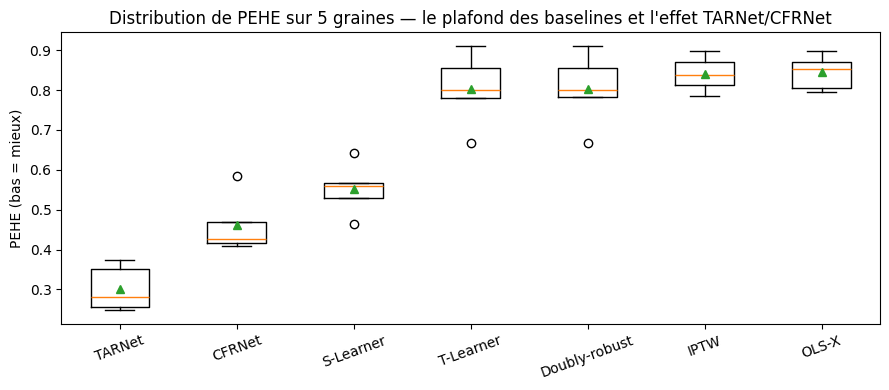

In [9]:
summary = (res.groupby("estimator")
             .agg(pehe_med=("pehe", "median"),
                  pehe_q1=("pehe", lambda s: s.quantile(0.25)),
                  pehe_q3=("pehe", lambda s: s.quantile(0.75)),
                  ate_err_med=("ate_err", "median"))
             .assign(pehe_iqr=lambda d: d.pehe_q3 - d.pehe_q1)
             .sort_values("pehe_med"))

print("Verdict sur 5 graines — PEHE (median [IQR]) et erreur d'ATE mediane :")
print(f"{'estimateur':<16} {'PEHE med':>9} {'IQR':>7} {'ATE err':>8}")
for name, row in summary.iterrows():
    print(f"{name:<16} {row.pehe_med:>9.3f} {row.pehe_iqr:>7.3f} {row.ate_err_med:>8.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
order = summary.index.tolist()
data = [res[res.estimator == n].pehe.values for n in order]
ax.boxplot(data, tick_labels=order, showmeans=True)
ax.set_ylabel("PEHE (bas = mieux)")
ax.set_title("Distribution de PEHE sur 5 graines — le plafond des baselines et l'effet TARNet/CFRNet")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Lecture attendue** (les valeurs exactes varient avec les graines, c'est pourquoi 5 graines et un IQR) : les estimateurs à effet constant (OLS-X, IPTW) portent une PEHE de l'ordre de l'écart-type de $\tau$ (~0,86) — ils ne prédisent aucune hétérogénéité. Les arbres boostés (S/T-Learner, doubly-robust) améliorent sans inventer de représentation. TARNet **régularisé** (dropout 0,5 + ℓ2) passe sous tout ce tableau — sans régularisation il serait dernier de la classe (mesuré en amont du carnet : PEHE 1,54 — hors tableau, la section 6 n'évalue que le réseau régularisé). CFRNet, sur **cette** réplique, se place légèrement derrière TARNet : la pénalité MMD linéaire aligne les moyennes des représentations, ce qui coûte en fidélité plus qu'elle ne gagne en équilibre ici — un résultat rapporté aussi dans la littérature sur une partie des répliques.

## 7. Verdict — quand le neuronal gagne, et quand il ne gagne pas

Quatre constats mesurés sur ce banc :

1. **Le plafond des estimateurs constants est structurel.** OLS-X et IPTW rendent un nombre ; sur un banc où l'écart-type de $\tau$ vaut ~0,86, aucune feature ne les sauve — il leur manque la *forme fonctionnelle* du CATE.
2. **La régularisation fait l'estimateur, pas l'architecture.** Le même TARNet passe de PEHE 1,54 (mesuré en amont, hors carnet : sans dropout ni ℓ2) à ~0,3 (premier du tableau, section 7) : sur 523 unités, un réseau sur-paramétré fite l'outcome et rate l'effet. C'est la leçon que ce carnet existe pour rendre visible — lire « neural » dans un tableau de banc sans lire le régime de régularisation est une erreur de lecture.
3. **Le partage de représentation paie une fois régularisé** : TARNet vs S-Learner/T-Learner isole l'effet du tronc commun à capacité comparable.
4. **L'IPM n'est pas une garantie** : sur cette réplique, CFRNet (α=1) reste derrière TARNet — la MMD linéaire aligne les moyennes, pas les distributions. La littérature rapporte les deux signes selon les répliques ; l'exercice 1 mesure le balayage d'α.

**Limites déclarées** : une seule réplique IHDP (le banc standard en compte 100) ; pas d'early stopping ; α fixé sans validation croisée ; CPU seulement. Les conclusions portent sur les **écarts entre méthodes** et les mécanismes mesurés, pas sur les valeurs absolues.

## 8. Second banc — ACIC 2016 : le verdict survit-il au changement de données ?

IHDP est **un** semi-synthétique de 747 unités — un seul point dans l'espace des mécanismes de génération. Le data challenge de l'Atlantic Causal Inference Conference 2016 (Dorie, Hill, Shalit, Scott & Cervone, 2019) a été construit exactement pour couvrir cet espace : 4 802 unités réelles, 58 covariables, et des dizaines de simulations qui varient selon **cinq axes** — non-linéarité de la réponse, recouvrement/déséquilibre du traitement, proportion traitée, alignement assignment/réponse, hétérogénéité de l'effet. C'est le banc qui a servi de terrain à la compétition « automated versus do-it-yourself » : aucun estimateur n'y domine partout, et le papier de référence analyse pourquoi.

**Provenance et licence.** Le sous-ensemble utilisé ici est redistribué depuis `causallib/datasets/data/acic_challenge_2016/` (dépôt GitHub `BiomedSciAI/causallib`) : `x.csv` — les 58 covariables réelles (catégorielles codées A/B/C…, binaires 0/1, réelles brutes) — et trois des dix simulations livrées (`zymu_1`, `zymu_5`, `zymu_10`), chacune portant le traitement `z`, les outcomes potentiels bruités `y0`/`y1` et les surfaces **espérées** `mu0`/`mu1` — d'où un CATE vrai exact par unité : $\tau(x) = \mu_1(x) - \mu_0(x)$. Les données du challenge sont distribuées sous **CDLA-Sharing-1.0** (fichier `LICENSE` committé à côté des CSV, avec le `README.md` du bundle) ; le générateur officiel complet est `vdorie/aciccomp` (dossier `2016`). Empreintes sha256 calculées à l'exécution dans la cellule suivante.

**Deux déviations déclarées avec le banc IHDP.** (i) Les estimateurs ne changent pas d'un iota — mêmes baselines, mêmes TARNet/CFRNet ; seuls les hyperparamètres d'entraînement s'adaptent : 200 époques et batch 256 au lieu de 500 et 100, soit ~2 800 pas de gradient par fit contre ~3 000 sur IHDP — le budget d'optimisation est maintenu, pas réduit — et `d_in` passe de 25 à 82 après encodage. (ii) La propension et la part traitée varient **entre simulations** — le carnet les mesure au lieu de les supposer.

zymu_1 : sha256 002fad96bb55d54e... | n=4802 | traites=17.9% | tau : moyenne=2.13 ecart-type=3.98 [-13.5, 10.8]
zymu_5 : sha256 e350ac76d0b8e83f... | n=4802 | traites=30.1% | tau : moyenne=3.35 ecart-type=4.53 [-11.7, 33.5]
zymu_10 : sha256 c8ee8ca537ef4315... | n=4802 | traites=24.8% | tau : moyenne=4.22 ecart-type=6.74 [-60.8, 27.3]
x.csv  : sha256 0d6387ad45d23e54... | 4802 lignes | 3 colonnes categorielles (x_2, x_21, x_24) -> 82 features apres one-hot


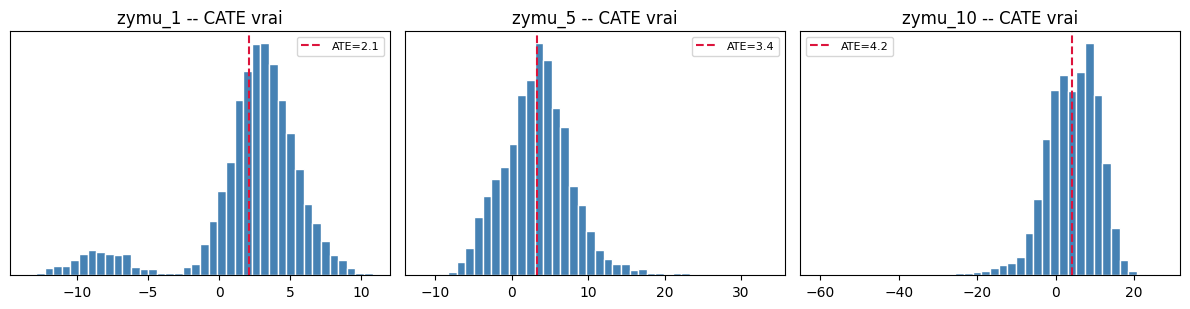

In [10]:
import hashlib

ACIC_DIR = Path("data/acic2016")

def _sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

xac = pd.read_csv(ACIC_DIR / "x.csv")
cat_cols = [c for c in xac.columns if not pd.api.types.is_numeric_dtype(xac[c])]
Xac = pd.get_dummies(xac, columns=cat_cols).astype("float64").to_numpy()

acic = {}
for k in (1, 5, 10):
    z = pd.read_csv(ACIC_DIR / f"zymu_{k}.csv")
    zk = z["z"].to_numpy(int)
    y0k, y1k = z["y0"].to_numpy(), z["y1"].to_numpy()
    acic[k] = dict(t=zk, y=np.where(zk == 1, y1k, y0k),
                   mu0=z["mu0"].to_numpy(), mu1=z["mu1"].to_numpy(),
                   tau=(z["mu1"] - z["mu0"]).to_numpy())
    d = acic[k]
    print(f"zymu_{k} : sha256 {_sha256(ACIC_DIR / f'zymu_{k}.csv')[:16]}... | "
          f"n={len(d['t'])} | traites={d['t'].mean():.1%} | "
          f"tau : moyenne={d['tau'].mean():.2f} ecart-type={d['tau'].std():.2f} "
          f"[{d['tau'].min():.1f}, {d['tau'].max():.1f}]")
print(f"x.csv  : sha256 {_sha256(ACIC_DIR / 'x.csv')[:16]}... | {xac.shape[0]} lignes | "
      f"{len(cat_cols)} colonnes categorielles ({', '.join(cat_cols)}) "
      f"-> {Xac.shape[1]} features apres one-hot")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, k in zip(axes, (1, 5, 10)):
    ax.hist(acic[k]["tau"], bins=40, color="steelblue", edgecolor="white")
    ax.axvline(acic[k]["tau"].mean(), color="crimson", ls="--",
               label=f"ATE={acic[k]['tau'].mean():.1f}")
    ax.set_title(f"zymu_{k} -- CATE vrai")
    ax.set_yticks([]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture du banc** : les trois simulations ne racontent pas la même histoire. La part traitée passe de 17,9 % (`zymu_1`) à 30,1 % (`zymu_5`) — le déséquilibre des bras varie d'un réglage à l'autre, là où IHDP était figé à 18,6 %. L'hétérogénéité monte d'un cran à chaque étape : l'écart-type de $\tau$ passe de 3,98 à 4,53 puis 6,74, et `zymu_10` porte des effets extrêmes (de $-60{,}8$ à $+27{,}3$) — un régime qu'IHDP, avec son écart-type de 0,86, ne peut pas produire. Conséquence mécanique : le plancher des estimateurs constants (prédire l'ATE partout) se déplace avec l'écart-type de $\tau$. Comparer des PEHE **entre** simulations brutes n'a donc pas de sens ; ce qui se compare, ce sont les écarts **entre estimateurs à simulation fixée** — c'est ainsi que le benchmark suivant se lit.

In [11]:
import time

ACIC_SEEDS = [0, 1, 7, 42, 99]

records_acic = []
t0 = time.perf_counter()

for k in (1, 5, 10):
    d = acic[k]
    for seed in ACIC_SEEDS:
        (Xtr, ttr, ytr, _, _, _,
         Xte, tte, yte, _, _, taute) = split_train_test(
            d["t"], Xac, d["y"], d["mu0"], d["mu1"], d["tau"], seed=seed)
        Xtr_s, Xte_s = standardize(Xtr, Xte)

        for name, fn in BASELINES.items():
            tau_hat = fn(Xtr_s, ttr, ytr, Xte_s)
            records_acic.append(dict(setting=f"zymu_{k}", seed=seed, estimator=name,
                                     pehe=pehe(tau_hat, taute), ate_err=ate_error(tau_hat, taute)))

        for name, cls, alpha in (("TARNet", TARNet, 0.0), ("CFRNet", CFRNet, 1.0)):
            ym, ys = ytr.mean(), ytr.std()
            model = fit_neural(cls, Xtr_s, ttr, (ytr - ym) / ys, seed=seed, ipm_alpha=alpha,
                               d_in=Xtr_s.shape[1], epochs=200, batch=256)
            tau_hat = net_tau(model, Xte_s, y_sd=ys)
            records_acic.append(dict(setting=f"zymu_{k}", seed=seed, estimator=name,
                                     pehe=pehe(tau_hat, taute), ate_err=ate_error(tau_hat, taute)))

res_acic = pd.DataFrame(records_acic)
print(f"benchmark ACIC termine en {time.perf_counter() - t0:.1f}s -- {len(res_acic)} mesures")
res_acic.head()

benchmark ACIC termine en 1927.2s -- 105 mesures


,setting,seed,estimator,pehe,ate_err
0,zymu_1,0,OLS-X,3.921737,0.435192
1,zymu_1,0,T-Learner,1.019169,0.366880
2,zymu_1,0,S-Learner,1.164908,0.343869
3,zymu_1,0,IPTW,3.963656,0.721069
4,zymu_1,0,Doubly-robust,1.037972,0.416271


ACIC 2016 -- PEHE (mediane [IQR]) et erreur d'ATE mediane, par simulation :

-- zymu_1 --
estimateur        PEHE med     IQR  ATE err
Doubly-robust        1.038   0.036    0.416
T-Learner            1.039   0.046    0.399
S-Learner            1.165   0.030    0.341
TARNet               1.519   0.121    0.291
CFRNet               1.809   0.046    0.703
IPTW                 3.993   0.046    0.627
OLS-X                3.996   0.024    0.535

-- zymu_5 --
estimateur        PEHE med     IQR  ATE err
Doubly-robust        0.964   0.091    0.148
T-Learner            0.970   0.091    0.189
S-Learner            1.848   0.130    0.108
TARNet               1.877   0.088    0.107
CFRNet               2.469   0.170    0.352
OLS-X                4.544   0.028    0.444
IPTW                 4.563   0.010    0.361

-- zymu_10 --
estimateur        PEHE med     IQR  ATE err
Doubly-robust        1.479   0.413    0.119
T-Learner            1.480   0.409    0.150
S-Learner            2.133   0.426    0.268
T

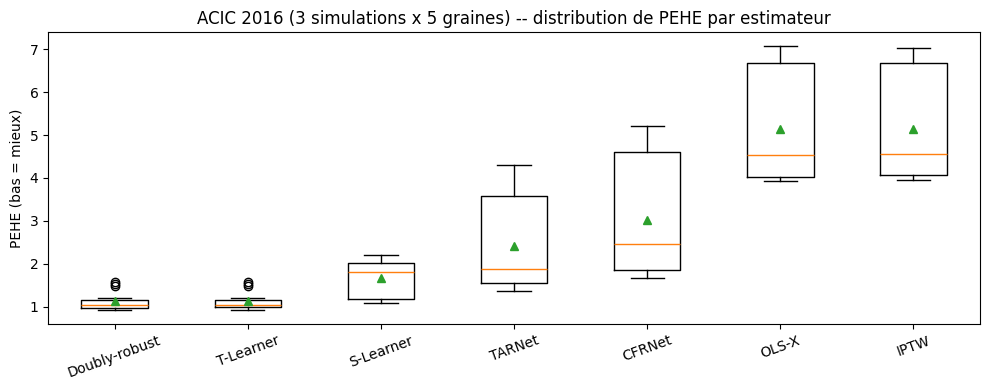

In [12]:
summary_acic = (res_acic.groupby(["setting", "estimator"])
                .agg(pehe_med=("pehe", "median"),
                     pehe_q1=("pehe", lambda s: s.quantile(0.25)),
                     pehe_q3=("pehe", lambda s: s.quantile(0.75)),
                     ate_err_med=("ate_err", "median"))
                .assign(pehe_iqr=lambda d: d.pehe_q3 - d.pehe_q1))

print("ACIC 2016 -- PEHE (mediane [IQR]) et erreur d'ATE mediane, par simulation :")
for k in (1, 5, 10):
    sub = summary_acic.loc[f"zymu_{k}"].sort_values("pehe_med")
    print(f"\n-- zymu_{k} --")
    print(f"{'estimateur':<16} {'PEHE med':>9} {'IQR':>7} {'ATE err':>8}")
    for name, row in sub.iterrows():
        print(f"{name:<16} {row.pehe_med:>9.3f} {row.pehe_iqr:>7.3f} {row.ate_err_med:>8.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
order = (summary_acic.reset_index().groupby("estimator").pehe_med.median()
         .sort_values().index.tolist())
data = [res_acic[res_acic.estimator == n].pehe.values for n in order]
ax.boxplot(data, tick_labels=order, showmeans=True)
ax.set_ylabel("PEHE (bas = mieux)")
ax.set_title("ACIC 2016 (3 simulations x 5 graines) -- distribution de PEHE par estimateur")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Grille de lecture** : chaque bloc `zymu_k` se lit à simulation fixée, jamais en travers — chacun a son propre écart-type de $\tau$, donc son propre plancher pour les estimateurs constants. Trois lectures mesurées : (1) **le classement IHDP ne se reproduit pas** — sur les trois simulations, Doubly-robust et T-Learner dominent en PEHE (1.038/1.039 sur `zymu_1`, 0.964/0.970 sur `zymu_5`, 1.479/1.480 sur `zymu_10`) quand TARNet recule au milieu de tableau (1.519, 1.877, 3.987) et CFRNet ferme la marche des apprenants (1.809, 2.469, 4.904) : l'avantage des représentations partagées observé sur IHDP ne survit pas au changement de design ; (2) l'écart constantes/apprenants ne se referme pas — OLS-X reste à distance sur les trois blocs (3.996, 4.544, 6.874) et l'hétérogénéité montante de `zymu_10` creuse la PEHE de tout le monde sans changer l'ordre ; (3) PEHE et erreur d'ATE dissent visiblement sur CFRNet/`zymu_1` (PEHE médiane 1.809 mais erreur d'ATE 0.703, la plus forte du bloc) — la PEHE punit l'erreur individuelle, l'erreur d'ATE seulement le décalage de moyenne, et un estimateur peut mal faire aux deux pour des raisons différentes.

## 9. Exercices

Les exercices suivent la convention du dépôt : stubs sans erreur volontaire, le carnet s'exécute de bout en bout avant et après vos réponses.

In [13]:
# Exercice 1 : ablation de la penalite MMD. Entrainez CFRNet avec alpha in {0, 0.5, 1, 2}
# (3 graines suffisent). Sur cette replique, la PEHE mediane CROIT avec alpha (alpha=1 reste derriere
# alpha=0 au benchmark de la section 7 ; la tendance croissante est mesuree en amont, hors carnet) : la penalite aligne les moyennes des representations au prix de la fidelite
# factuelle. Trouvez-vous un regime (petit alpha, ou noyau non lineaire) ou CFRNet repasse
# devant TARNet ?
result_ex1 = None  # TODO etudiant : PEHE mediane par alpha, et verdict sur le signe
print("Exercice a completer : ablation MMD (alpha)")

Exercice a completer : ablation MMD (alpha)


In [14]:
# Exercice 2 : ablation du tronc partage. Definissez un T-Learner neuronal (deux TARNet
# independants, un par bras, sans representation commune) et comparez sa PEHE a TARNet.
# Le gain du tronc partage est-il visible sur les 5 graines ?
result_ex2 = None  # TODO etudiant : pehe mediane T-Learner neuronal vs TARNet
print("Exercice a completer : ablation shared-trunk")

Exercice a completer : ablation shared-trunk


In [15]:
# Exercice 3 : GANITE (Bica et al. 2018) -- generateur de contrefactuels + discriminateur.
# Esquisse : (a) un generateur G(x, t) propose le contrefactuel ; (b) un discriminateur
# distingue factual/contrefactuel genere ; (c) l'ITEs sont lus au sortie du generateur.
# Comparez PEHE a TARNet sur 3 graines. Le papier annonce un gain sur IHDP : le reproduisez-vous ?
result_ex3 = None  # TODO etudiant : PEHE GANITE vs TARNet
print("Exercice a completer : GANITE from scratch")

Exercice a completer : GANITE from scratch


In [16]:
# Exercice 4 : CEVAE simplifie (Louizos et al. 2017) -- VAE dont le facteur latent z
# porte a la fois le confondeur et l'heterogeneite. Encodeur q(z|x,t,y), decodeur p(x,y|z,t),
# prior p(z) -- et l'ITE estime par difference de decodages avec t=1 et t=0, z echantillonne.
# Comparez PEHE a TARNet ; discutez le cout (3 reseaux, plus d'hyperparametres).
result_ex4 = None  # TODO etudiant : PEHE CEVAE simplifie
print("Exercice a completer : CEVAE simplifie")

Exercice a completer : CEVAE simplifie


In [17]:
# Exercice 5 : Dragonnet (Shi et al. 2019) -- tronc partage + tete outcome + tete propension,
# regularisation ciblee : la propension predite est ajoutee a la loss d'outcome avec un poids
# epsilon. Mesurez PEHE pour epsilon in {0, 0.1, 1.0}. La regularisation ciblee aide-t-elle
# surtout sur les faibles chevauchements (strates a propension extreme) ?
result_ex5 = None  # TODO etudiant : PEHE Dragonnet par strate de propension
print("Exercice a completer : Dragonnet targeted regularization")

Exercice a completer : Dragonnet targeted regularization


## Bibliographie

- **Shalit, U., Johansson, F. D., & Sontag, D.** (2017). Estimating individual treatment effect: generalization bounds and algorithms. *ICML* — TARNet, CFRNet, bornes de généralisation de l'effet individuel. [arXiv:1606.03976](https://arxiv.org/abs/1606.03976)
- **Johansson, F. D., Shalit, U., & Sontag, D.** (2016). Learning representations for counterfactual inference. *ICML* — la première formulation de la régression contrefactuelle par représentation. [arXiv:1605.03661](https://arxiv.org/abs/1605.03661)
- **Louizos, C., et al.** (2017). Causal effect inference with deep latent-variable models. *NeurIPS* — CEVAE. [arXiv:1705.08821](https://arxiv.org/abs/1705.08821)
- **Shi, C., Blei, D., & Veitch, V.** (2019). Adapting neural networks for the estimation of treatment effects. *NeurIPS* — Dragonnet, régularisation ciblée. [arXiv:1906.02120](https://arxiv.org/abs/1906.02120)
- **Bica, I., Alaa, A. M., & van der Schaar, M.** (2018). Estimating individualized treatment effects using generative adversarial nets. *ICLR* — GANITE. Application santé : Bica et al., *JAMIA* (2020).
- **Hill, J. L.** (2011). Bayesian nonparametric modeling for causal inference. *JCGS* 20(1) — le banc IHDP (outcomes gonflés, traitement biaisé).
- **Künzel, S., et al.** (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. *PNAS* — T-Learner, S-Learner, X-Learner.
- **Dorie, V., Hill, J., Shalit, U., Scott, M., & Cervone, D.** (2019). Automated versus do-it-yourself methods for causal inference: Lessons learned from a competition. *Statistical Science* 34(1) — le data challenge ACIC 2016 : 4 802 unités réelles, simulations à cinq axes de variation, générateur `vdorie/aciccomp`.

***

*Pli 3 / 9 de l'EPIC [#19309](https://github.com/jsboige/CoursIA/issues/19309) — angle mort : le CATE et son estimation par représentation (TARNet, CFRNet).*

[← Série Causal-Bridges](README.md) | [CB-10 Automated Social Science ←](CausalBridges-10-Automated-Social-Science.ipynb)